# Online Retail II - Data Cleaning, EDA and Data Validation

Dataset: online_retail_II.csv (sales of an online gift shop, Dec 2009 to Dec 2011)

Steps: CSV → PostgreSQL → Data Cleaning → EDA → SQL customer queries → Data Validation → Save files

## 1. Import libraries

In [1]:
import os
import io
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
from sqlalchemy import create_engine, text
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## 2. Load the raw CSV into PostgreSQL

Change the details below to match your PostgreSQL installation (the same username and password you use in pgAdmin).
The database `online_retail` is created automatically if it does not exist.

Libraries needed (install once): `pip install pandas matplotlib sqlalchemy psycopg2-binary scikit-learn numpy`

In [ ]:
# PostgreSQL connection settings. Set PG_PASSWORD in your environment before running.
# Example (Linux/macOS): export PG_PASSWORD="your_password"
# Example (Windows PowerShell): $env:PG_PASSWORD="your_password"
from sqlalchemy.engine import URL

DB_HOST = os.environ.get('PG_HOST', 'localhost')
DB_PORT = int(os.environ.get('PG_PORT', '5432'))
DB_USER = os.environ.get('PG_USER', 'postgres')
DB_PASSWORD = os.environ.get('PG_PASSWORD')
DB_NAME = os.environ.get('PG_DATABASE', 'online_retail')

if not DB_PASSWORD:
    raise EnvironmentError('Set the PG_PASSWORD environment variable before running this notebook.')

CSV_FILE = 'online_retail_II.csv'


In [ ]:
# Create the database if it does not exist.
conn = psycopg2.connect(host=DB_HOST, port=DB_PORT, user=DB_USER,
                        password=DB_PASSWORD, dbname='postgres')
conn.autocommit = True
cur = conn.cursor()
cur.execute('SELECT 1 FROM pg_database WHERE datname = %s', (DB_NAME,))
if cur.fetchone() is None:
    # DB_NAME comes from a local environment setting; quote it as an identifier.
    safe_db_name = psycopg2.extensions.quote_ident(DB_NAME, cur)
    cur.execute(f'CREATE DATABASE {safe_db_name}')
    print('Database created:', DB_NAME)
else:
    print('Database already exists:', DB_NAME)
cur.close()
conn.close()

engine_url = URL.create(
    drivername='postgresql+psycopg2', username=DB_USER, password=DB_PASSWORD,
    host=DB_HOST, port=DB_PORT, database=DB_NAME
)
engine = create_engine(engine_url)


In [ ]:
# Recreate the raw staging table. Keep DROP and CREATE as separate statements
# because PostgreSQL prepared statements may reject multiple commands at once.
with engine.begin() as con:
    con.execute(text('DROP TABLE IF EXISTS raw_online_retail'))
    con.execute(text("""
CREATE TABLE raw_online_retail (
    invoice       VARCHAR(10),
    stock_code    VARCHAR(20),
    description   TEXT,
    quantity      INTEGER,
    invoice_date  TIMESTAMP,
    price         DOUBLE PRECISION,
    customer_id   DOUBLE PRECISION,
    country       VARCHAR(50)
)
"""))
print('Table raw_online_retail created')

In [5]:
# load the CSV into the table with COPY (much faster than inserting row by row)
conn = psycopg2.connect(host=DB_HOST, port=DB_PORT, user=DB_USER, password=DB_PASSWORD, dbname=DB_NAME)
cur = conn.cursor()
with open(CSV_FILE, 'r', encoding='utf-8') as f:
    cur.copy_expert('COPY raw_online_retail FROM STDIN WITH (FORMAT csv, HEADER true)', f)
conn.commit()
conn.close()

with engine.connect() as con:
    print('Rows loaded into PostgreSQL:', con.execute(text('SELECT COUNT(*) FROM raw_online_retail')).scalar())

Rows loaded into PostgreSQL: 1067371


In [6]:
# read the raw data from PostgreSQL into pandas
df = pd.read_sql('SELECT * FROM raw_online_retail', engine)

df = df.rename(columns={'invoice': 'Invoice', 'stock_code': 'StockCode', 'description': 'Description',
                        'quantity': 'Quantity', 'invoice_date': 'InvoiceDate', 'price': 'Price',
                        'customer_id': 'CustomerID', 'country': 'Country'})
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
# check: the data in PostgreSQL is the same as the CSV file
csv_check = pd.read_csv(CSV_FILE, dtype={'Invoice': str, 'StockCode': str})
print('Rows in CSV       :', len(csv_check))
print('Rows in PostgreSQL:', len(df))
print('Quantity total CSV / PostgreSQL:', csv_check['Quantity'].sum(), '/', df['Quantity'].sum())
print('Missing CustomerID CSV / PostgreSQL:', csv_check['Customer ID'].isnull().sum(), '/', df['CustomerID'].isnull().sum())

Rows in CSV       : 1067371
Rows in PostgreSQL: 1067371
Quantity total CSV / PostgreSQL: 10608492 / 10608492
Missing CustomerID CSV / PostgreSQL: 243007 / 243007


## 3. Understand the data

In [8]:
raw_rows = len(df)
print('Rows and columns:', df.shape)

Rows and columns: (1067371, 8)


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 65.1 MB


In [10]:
# missing values in each column
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
CustomerID     243007
Country             0
dtype: int64

In [11]:
df.describe()

,Quantity,InvoiceDate,Price,CustomerID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [12]:
print('Duplicate rows:', df.duplicated().sum())
print('Cancelled rows (Invoice starts with C):', df['Invoice'].str.startswith('C').sum())
print('Rows with Quantity <= 0:', (df['Quantity'] <= 0).sum())
print('Rows with Price <= 0:', (df['Price'] <= 0).sum())

Duplicate rows: 34335
Cancelled rows (Invoice starts with C): 19494
Rows with Quantity <= 0: 22950
Rows with Price <= 0: 6207


**Problems found:**
- Description and CustomerID have missing values
- There are duplicate rows
- Quantity and Price have negative and zero values
- Invoices starting with 'C' are cancelled orders, 'A' are accounting adjustments
- Some stock codes are not products (postage, fees, manual entries)
- Text has extra spaces, stock codes are in mixed case, some country names are old codes (EIRE, RSA)

## 4. Data Cleaning

Every step that removes rows is saved in `removal_log` with the reason and the percentage of raw rows removed.

In [13]:
removal_log = []

def log_step(step, reason, rows_before):
    removed = rows_before - len(df)
    removal_log.append({'Step': step, 'Reason': reason, 'Rows removed': removed,
                        '% of raw rows': round(removed / raw_rows * 100, 2), 'Rows left': len(df)})
    print(f'{step}: removed {removed} rows ({removed / raw_rows * 100:.2f}%), rows left {len(df)}')

### 4.1 Remove duplicate rows

In [14]:
before = len(df)
df = df.drop_duplicates()
log_step('Duplicate rows', 'Same row recorded twice, would count the sale two times', before)

Duplicate rows: removed 34335 rows (3.22%), rows left 1033036


### 4.2 Fix text (no rows removed)

In [15]:
df['Invoice'] = df['Invoice'].str.strip()
df['StockCode'] = df['StockCode'].str.strip().str.upper()     # 85114b and 85114B are the same product
df['Description'] = df['Description'].astype('string').str.strip()
df['Description'] = df['Description'].replace('', pd.NA)
df['Country'] = df['Country'].str.strip().replace({'EIRE': 'Ireland', 'RSA': 'South Africa'})

### 4.3 Handle missing Description
1. If the same StockCode has a description in other rows, use the most common one.
2. If the StockCode has no description anywhere, the product is unknown, so the row is removed.

In [ ]:
print('Missing Description before:', df['Description'].isna().sum())

# Most common non-empty description for each StockCode.
def most_common_description(values):
    modes = values.dropna().mode()
    return modes.iloc[0] if not modes.empty else pd.NA

code_names = df.groupby('StockCode')['Description'].agg(most_common_description)
missing = df['Description'].isna()
df.loc[missing, 'Description'] = df.loc[missing, 'StockCode'].map(code_names)
filled = int(missing.sum() - df['Description'].isna().sum())
print('Filled from the same StockCode:', filled)
print('Still missing (unknown product):', df['Description'].isna().sum())


In [17]:
# what do the rows with missing Description look like?
df_missing = df[missing]
print('Price of these rows:', df_missing['Price'].unique())
print('Rows with CustomerID:', df_missing['CustomerID'].notnull().sum())

Price of these rows: [0.]
Rows with CustomerID: 0


All rows that had no Description have Price = 0 and no customer, so they are stock notes, not real sales.

In [18]:
before = len(df)
df = df.dropna(subset=['Description'])
log_step('Missing Description', 'StockCode has no description anywhere, product cannot be identified', before)
print('Missing Description after:', df['Description'].isnull().sum())

Missing Description: removed 361 rows (0.03%), rows left 1032675


Missing Description after: 0


### 4.4 Cancelled orders (Invoice starts with C)

In [19]:
before = len(df)
cancelled = df[df['Invoice'].str.startswith('C')].copy()
df = df[~df['Invoice'].str.startswith('C')]
log_step('Cancelled orders', 'Order was cancelled, not a sale (kept in a separate cancellations table)', before)

Cancelled orders: removed 19104 rows (1.79%), rows left 1013571


### 4.5 Accounting adjustments (Invoice starts with A)

In [20]:
df[df['Invoice'].str.startswith('A')][['Invoice', 'StockCode', 'Description', 'Price']]

,Invoice,StockCode,Description,Price
179406,A506401,B,Adjust bad debt,-53594.36
276274,A516228,B,Adjust bad debt,-44031.79
403472,A528059,B,Adjust bad debt,-38925.87
825443,A563185,B,Adjust bad debt,11062.06
825444,A563186,B,Adjust bad debt,-11062.06
825445,A563187,B,Adjust bad debt,-11062.06


In [21]:
before = len(df)
df = df[~df['Invoice'].str.startswith('A')]
log_step('Bad-debt adjustments', "'Adjust bad debt' accounting entries, not customer purchases", before)

Bad-debt adjustments: removed 6 rows (0.00%), rows left 1013565


### 4.6 Invalid records: Quantity or Price is 0 or negative

In [22]:
invalid = df[(df['Quantity'] <= 0) | (df['Price'] <= 0)]
print('Quantity <= 0:', (invalid['Quantity'] <= 0).sum())
print('Price <= 0   :', (invalid['Price'] <= 0).sum())
invalid['Description'].value_counts().head(10)

Quantity <= 0: 3092
Price <= 0   : 5653


Description
check                    160
?                         91
damages                   84
damaged                   81
found                     28
missing                   27
sold as set on dotcom     20
CHILLI LIGHTS             17
Damaged                   17
adjustment                16
Name: count, dtype: int64

These rows are stock notes like *damaged, check, missing* or free items. A real sale must have Quantity > 0 and Price > 0.

In [23]:
before = len(df)
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]
log_step('Invalid Quantity/Price', 'Quantity or Price is 0 or negative: stock adjustments and free items, no revenue', before)

Invalid Quantity/Price: removed 5653 rows (0.53%), rows left 1007912


### 4.7 Non-product codes

In [24]:
not_products = ['POST', 'DOT', 'M', 'C2', 'D', 'S', 'BANK CHARGES', 'ADJUST', 'ADJUST2',
                'AMAZONFEE', 'PADS', 'CRUK', 'B', 'TEST001', 'TEST002']

is_not_product = df['StockCode'].isin(not_products) | df['StockCode'].str.startswith('GIFT')
df[is_not_product].groupby('StockCode').agg(Description=('Description', 'first'), Rows=('Invoice', 'count')).sort_values('Rows', ascending=False)

,Description,Rows
StockCode,,
POST,POSTAGE,1851
DOT,DOTCOM POSTAGE,1415
M,Manual,851
C2,CARRIAGE,267
ADJUST,Adjustment by john on 26/01/2010 16,36
BANK CHARGES,Bank Charges,34
GIFT_0001_20,Dotcomgiftshop Gift Voucher £20.00,26
GIFT_0001_30,Dotcomgiftshop Gift Voucher £30.00,24
PADS,PADS TO MATCH ALL CUSHIONS,17


| Code | Meaning | Why removed |
|---|---|---|
| POST, DOT, C2 | Postage and carriage charges | Delivery charge, not a product |
| M | Manual entry | Manual price corrections, no real product |
| D | Discount | Price reduction, not a product |
| S | Samples | Free samples |
| BANK CHARGES, AMAZONFEE, CRUK | Bank, Amazon and charity fees | Fees, not products |
| ADJUST, ADJUST2, B | Adjustments | Accounting entries |
| TEST001, TEST002 | Test product | System testing |
| PADS | Cushion pads (sold at £0.001) | Filler item with almost no price |
| GIFT_... | Gift vouchers | Voucher, not a product |

In [25]:
before = len(df)
df = df[~is_not_product]
log_step('Non-product codes', 'Postage, fees, discounts, manual entries, tests and vouchers are not products', before)

# remove them from the cancelled table too
cancelled = cancelled[~(cancelled['StockCode'].isin(not_products) | cancelled['StockCode'].str.startswith('GIFT'))]
print('Cancelled product rows kept:', len(cancelled))

Non-product codes: removed 4572 rows (0.43%), rows left 1003340
Cancelled product rows kept: 17914


### 4.8 Outliers
I use the IQR rule to find unusually big quantities: Q3 + 1.5 × IQR.

In [26]:
Q1 = df['Quantity'].quantile(0.25)
Q3 = df['Quantity'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

outliers = df[df['Quantity'] > upper_limit]
print('Upper limit:', upper_limit)
print('Outlier rows:', len(outliers), f'({len(outliers) / len(df) * 100:.2f}% of rows)')

Upper limit: 28.5
Outlier rows: 53019 (5.28% of rows)


About 5% of rows are above the limit. Many customers are **wholesalers**, so buying 50 or 100 units is normal.
That is why I do **not** remove all IQR outliers. I only check the biggest ones.

In [27]:
df.sort_values('Quantity', ascending=False).head(5)[['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'CustomerID']]

,Invoice,StockCode,Description,Quantity,InvoiceDate,CustomerID
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,16446.0
587086,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,12346.0
90868,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,13902.0
127178,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,13902.0
127176,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,13902.0


In [28]:
# were the two biggest orders cancelled later?
cancelled[cancelled['Quantity'] <= -70000][['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'CustomerID']]

,Invoice,StockCode,Description,Quantity,InvoiceDate,CustomerID
587091,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,12346.0
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,16446.0


The orders of **80,995** and **74,215** units were cancelled by the same customer a few minutes later (C581484 and C541433).
They are data entry mistakes, so I remove them. The other large orders are kept because they are real wholesale orders.

In [29]:
before = len(df)
df = df[df['Quantity'] < 70000]
log_step('Outliers', 'Two huge orders (80,995 and 74,215 units) cancelled minutes later: data entry mistakes', before)

Outliers: removed 2 rows (0.00%), rows left 1003338


### 4.9 Check duplicates again (after fixing text)

In [30]:
before = len(df)
df = df.drop_duplicates()
log_step('Duplicates after text fix', 'Rows that became identical after removing spaces and fixing stock code case', before)

Duplicates after text fix: removed 0 rows (0.00%), rows left 1003338


### 4.10 Missing CustomerID
These rows are real sales from guest customers, so I **keep** them. Removing them would show less revenue than the company made.
For customer analysis and the SQL customer queries I use only rows with a CustomerID.

In [31]:
df['CustomerID'] = df['CustomerID'].astype('Int64')
print('Rows without CustomerID:', df['CustomerID'].isnull().sum(), f"({df['CustomerID'].isnull().mean() * 100:.1f}%)")

Rows without CustomerID: 226761 (22.6%)


### 4.11 Add new columns

In [32]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Revenue'] = (df['Quantity'] * df['Price']).round(2)
df['Month'] = df['InvoiceDate'].dt.to_period('M')
df['Day'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

cancelled['CustomerID'] = cancelled['CustomerID'].astype('Int64')
cancelled['Revenue'] = (cancelled['Quantity'] * cancelled['Price']).round(2)
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue,Month,Day,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12,Tuesday,7


### 4.12 Cleaning summary: rows removed and why

In [33]:
removal = pd.DataFrame(removal_log)
total = pd.DataFrame([{'Step': 'TOTAL', 'Reason': '', 'Rows removed': removal['Rows removed'].sum(),
                       '% of raw rows': round(removal['Rows removed'].sum() / raw_rows * 100, 2), 'Rows left': len(df)}])
removal = pd.concat([removal, total], ignore_index=True)

print('Raw rows  :', raw_rows)
print('Clean rows:', len(df))
pd.set_option('display.max_colwidth', 120)
removal

Raw rows  : 1067371
Clean rows: 1003338


,Step,Reason,Rows removed,% of raw rows,Rows left
0,Duplicate rows,"Same row recorded twice, would count the sale two times",34335,3.22,1033036
1,Missing Description,"StockCode has no description anywhere, product cannot be identified",361,0.03,1032675
2,Cancelled orders,"Order was cancelled, not a sale (kept in a separate cancellations table)",19104,1.79,1013571
3,Bad-debt adjustments,"'Adjust bad debt' accounting entries, not customer purchases",6,0.00,1013565
4,Invalid Quantity/Price,"Quantity or Price is 0 or negative: stock adjustments and free items, no revenue",5653,0.53,1007912
5,Non-product codes,"Postage, fees, discounts, manual entries, tests and vouchers are not products",4572,0.43,1003340
6,Outliers,"Two huge orders (80,995 and 74,215 units) cancelled minutes later: data entry mistakes",2,0.00,1003338
7,Duplicates after text fix,Rows that became identical after removing spaces and fixing stock code case,0,0.00,1003338
8,TOTAL,,64033,6.00,1003338


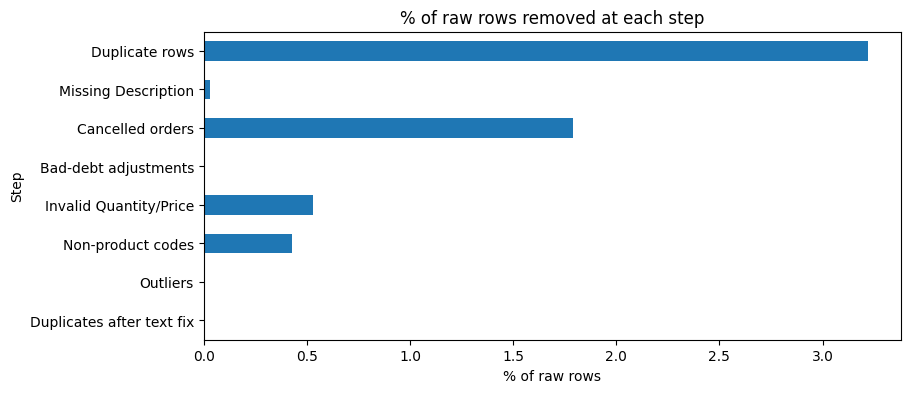

In [34]:
removal[removal['Step'] != 'TOTAL'].plot(x='Step', y='% of raw rows', kind='barh', legend=False, figsize=(9, 4))
plt.title('% of raw rows removed at each step')
plt.xlabel('% of raw rows')
plt.gca().invert_yaxis()
plt.show()

## 5. EDA

In [35]:
total_revenue = df['Revenue'].sum()
total_orders = df['Invoice'].nunique()
total_customers = df['CustomerID'].nunique()

print('Total revenue  :', round(total_revenue, 2))
print('Total orders   :', total_orders)
print('Total units    :', df['Quantity'].sum())
print('Total products :', df['StockCode'].nunique())
print('Total customers:', total_customers)
print('Total countries:', df['Country'].nunique())
print('Average order value:', round(total_revenue / total_orders, 2))

Total revenue  : 19398208.42
Total orders   : 39514
Total units    : 11032834
Total products : 4723
Total customers: 5852
Total countries: 43
Average order value: 490.92


### Monthly revenue

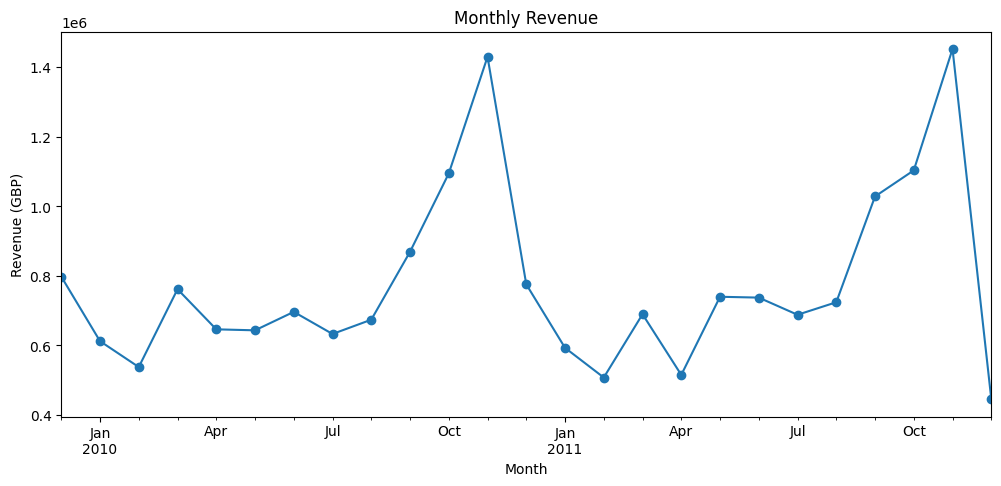

Top 3 months:
Month
2011-11    1452115.98
2010-11    1429700.78
2011-10    1103314.25
Freq: M, Name: Revenue, dtype: float64


In [36]:
monthly = df.groupby('Month')['Revenue'].sum()
monthly.plot(kind='line', marker='o', figsize=(12, 5))
plt.title('Monthly Revenue')
plt.ylabel('Revenue (GBP)')
plt.show()

print('Top 3 months:')
print(monthly.sort_values(ascending=False).head(3).round(2))

In [37]:
# compare the same months (Jan - Nov) of 2010 and 2011
rev_2010 = df[(df['InvoiceDate'].dt.year == 2010) & (df['InvoiceDate'].dt.month <= 11)]['Revenue'].sum()
rev_2011 = df[(df['InvoiceDate'].dt.year == 2011) & (df['InvoiceDate'].dt.month <= 11)]['Revenue'].sum()
print('Jan-Nov 2010:', round(rev_2010, 2))
print('Jan-Nov 2011:', round(rev_2011, 2))
print('Growth %    :', round((rev_2011 / rev_2010 - 1) * 100, 1))

Jan-Nov 2010: 8598741.14
Jan-Nov 2011: 8779906.44
Growth %    : 2.1


### Top 10 countries by revenue

In [38]:
country = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
country_share = (country / total_revenue * 100).round(1)
pd.DataFrame({'Revenue': country.round(2), '% share': country_share}).head(10)

,Revenue,% share
Country,,
United Kingdom,16555366.17,85.3
Ireland,623414.16,3.2
Netherlands,549773.41,2.8
Germany,383289.00,2.0
France,311090.29,1.6
Australia,167800.01,0.9
Spain,97766.75,0.5
Switzerland,94024.59,0.5
Sweden,86319.14,0.4


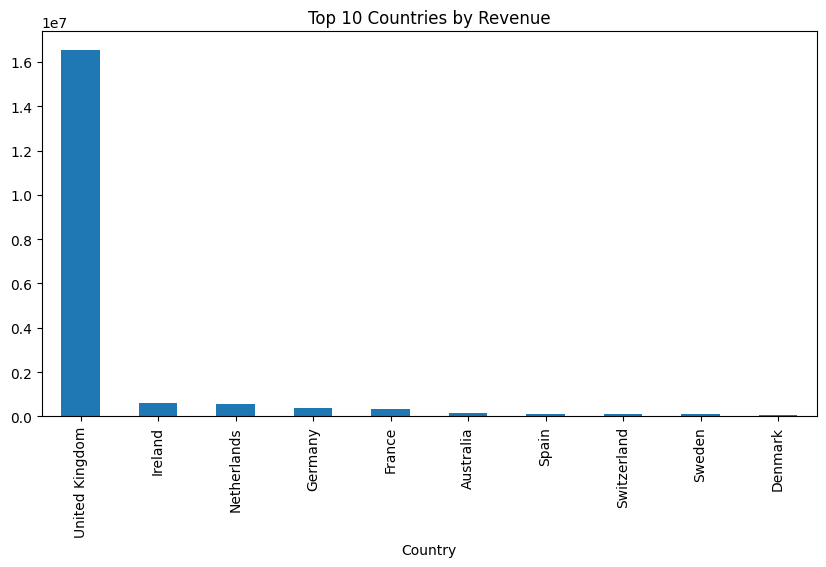

In [39]:
country.head(10).plot(kind='bar', figsize=(10, 5))
plt.title('Top 10 Countries by Revenue')
plt.show()

### Top 10 products

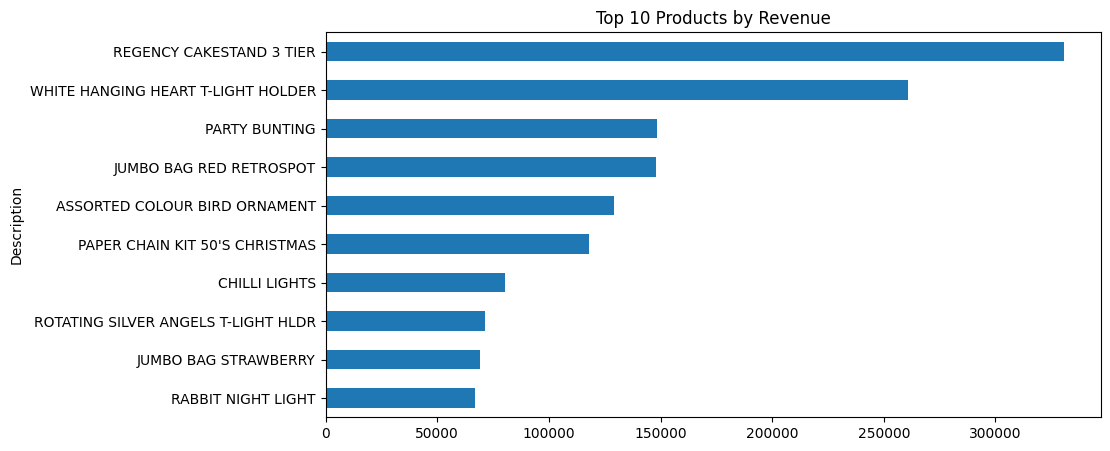

Description
REGENCY CAKESTAND 3 TIER               330590.32
WHITE HANGING HEART T-LIGHT HOLDER     260990.22
PARTY BUNTING                          148318.28
JUMBO BAG RED RETROSPOT                148073.47
ASSORTED COLOUR BIRD ORNAMENT          129324.49
PAPER CHAIN KIT 50'S CHRISTMAS         117760.29
CHILLI LIGHTS                           80540.88
ROTATING SILVER ANGELS T-LIGHT HLDR     71300.40
JUMBO BAG STRAWBERRY                    69002.13
RABBIT NIGHT LIGHT                      66870.03
Name: Revenue, dtype: float64

In [40]:
top_products = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)
top_products.plot(kind='barh', figsize=(10, 5))
plt.title('Top 10 Products by Revenue')
plt.gca().invert_yaxis()
plt.show()
top_products.round(2)

In [41]:
# top 10 by units sold
df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     106139
WHITE HANGING HEART T-LIGHT HOLDER     94658
ASSORTED COLOUR BIRD ORNAMENT          80082
JUMBO BAG RED RETROSPOT                77699
BROCADE RING PURSE                     70369
PACK OF 60 PINK PAISLEY CAKE CASES     56061
60 TEATIME FAIRY CAKE CASES            54028
SMALL POPCORN HOLDER                   48561
PACK OF 72 RETROSPOT CAKE CASES        48156
PACK OF 72 RETRO SPOT CAKE CASES       46728
Name: Quantity, dtype: int64

### Sales by day and hour

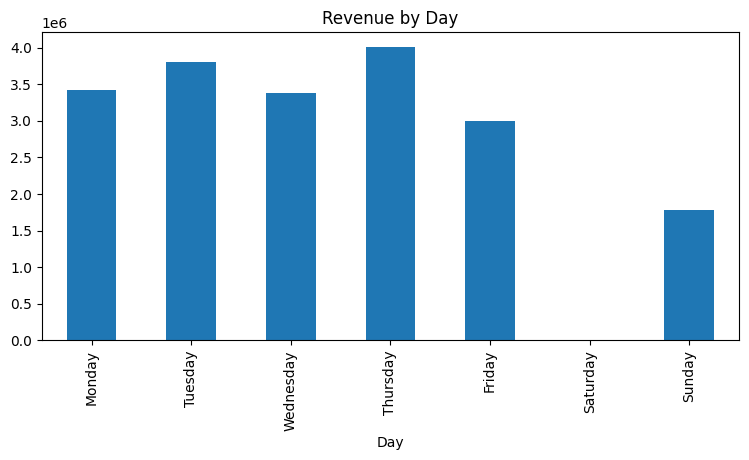

Orders on Saturday: 30


In [42]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = df.groupby('Day')['Revenue'].sum().reindex(days).fillna(0)
by_day.plot(kind='bar', figsize=(9, 4))
plt.title('Revenue by Day')
plt.show()
print('Orders on Saturday:', df[df['Day'] == 'Saturday']['Invoice'].nunique())

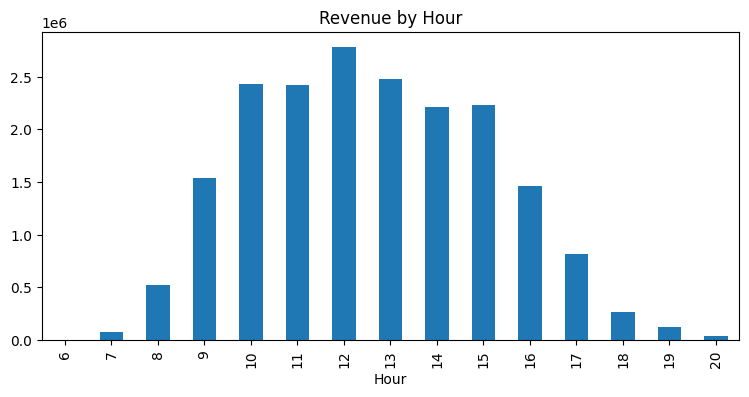

Best hour: 12


In [43]:
by_hour = df.groupby('Hour')['Revenue'].sum()
by_hour.plot(kind='bar', figsize=(9, 4))
plt.title('Revenue by Hour')
plt.show()
print('Best hour:', by_hour.idxmax())

### Customers

In [44]:
customers = df.dropna(subset=['CustomerID'])
orders_per_customer = customers.groupby('CustomerID')['Invoice'].nunique()

repeat_customers = (orders_per_customer > 1).sum()
print('Customers who ordered more than once:', repeat_customers)
print('Customers who ordered only once:', (orders_per_customer == 1).sum())
print('Repeat customer %:', round(repeat_customers / len(orders_per_customer) * 100, 1))

Customers who ordered more than once: 4233
Customers who ordered only once: 1619
Repeat customer %: 72.3


In [45]:
# top 10 customers
customers.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10).round(2)

CustomerID
18102    580987.04
14646    526751.52
14156    303069.88
14911    272252.79
17450    244784.25
13694    195640.69
17511    172132.87
16684    147142.77
12415    144033.37
15061    126387.57
Name: Revenue, dtype: float64

### Cancelled orders

In [46]:
print('Cancelled invoices:', cancelled['Invoice'].nunique())
print('Cancelled value   :', round(-cancelled['Revenue'].sum(), 2))
print('Cancelled value as % of sales:', round(-cancelled['Revenue'].sum() / total_revenue * 100, 1))
cancelled['Description'].value_counts().head(10)

Cancelled invoices: 7405
Cancelled value   : 716425.97
Cancelled value as % of sales: 3.7


Description
REGENCY CAKESTAND 3 TIER              341
BAKING SET 9 PIECE RETROSPOT          209
STRAWBERRY CERAMIC TRINKET BOX        181
WHITE HANGING HEART T-LIGHT HOLDER    134
WHITE CHERRY LIGHTS                   126
RED RETROSPOT CAKE STAND              107
JAM MAKING SET WITH JARS               87
PINK CHERRY LIGHTS                     86
WOOD 2 DRAWER CABINET WHITE FINISH     85
SWEETHEART CERAMIC TRINKET BOX         73
Name: count, dtype: int64

## 6. SQL queries: customer-level data

The cleaned data and the cancelled orders are loaded into PostgreSQL. Then SQL queries extract the customer-level data.

In [ ]:
def load_to_postgres(data, table_name, create_sql):
    """Replace a PostgreSQL table and bulk-load a pandas DataFrame into it."""
    allowed_tables = {'clean_sales', 'cancelled_orders'}
    if table_name not in allowed_tables:
        raise ValueError(f'Unexpected table name: {table_name}')

    with engine.begin() as con:
        con.execute(text(f'DROP TABLE IF EXISTS {table_name}'))
        con.execute(text(create_sql))

    buffer = io.StringIO()
    data.to_csv(buffer, index=False, header=False)
    buffer.seek(0)
    conn = psycopg2.connect(host=DB_HOST, port=DB_PORT, user=DB_USER,
                            password=DB_PASSWORD, dbname=DB_NAME)
    try:
        with conn.cursor() as cur:
            cur.copy_expert(f'COPY {table_name} FROM STDIN WITH (FORMAT csv)', buffer)
        conn.commit()
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()

columns = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'Revenue']
table_sql = """
CREATE TABLE {name} (
    invoice       VARCHAR(10),
    stock_code    VARCHAR(20),
    description   TEXT,
    quantity      INTEGER,
    invoice_date  TIMESTAMP,
    price         NUMERIC(12,2),
    customer_id   INTEGER,
    country       VARCHAR(50),
    revenue       NUMERIC(14,2)
)
"""
load_to_postgres(df[columns], 'clean_sales', table_sql.format(name='clean_sales'))
load_to_postgres(cancelled[columns], 'cancelled_orders', table_sql.format(name='cancelled_orders'))

with engine.connect() as con:
    print('clean_sales rows     :', con.execute(text('SELECT COUNT(*) FROM clean_sales')).scalar())
    print('cancelled_orders rows:', con.execute(text('SELECT COUNT(*) FROM cancelled_orders')).scalar())


### Query 1: Customer summary (one row per customer)

In [48]:
q1_customer_summary = '''
SELECT
    s.customer_id,
    MODE() WITHIN GROUP (ORDER BY s.country)            AS country,
    COUNT(DISTINCT s.invoice)                           AS total_orders,
    SUM(s.quantity)                                     AS total_units,
    ROUND(SUM(s.revenue), 2)                            AS total_revenue,
    ROUND(SUM(s.revenue) / COUNT(DISTINCT s.invoice), 2) AS avg_order_value,
    MIN(s.invoice_date)                                 AS first_purchase,
    MAX(s.invoice_date)                                 AS last_purchase,
    DATE_PART('day', (SELECT MAX(invoice_date) FROM clean_sales) - MAX(s.invoice_date)) AS days_since_last_purchase,
    COALESCE(c.cancelled_orders, 0)                     AS cancelled_orders
FROM clean_sales s
LEFT JOIN (
    SELECT customer_id, COUNT(DISTINCT invoice) AS cancelled_orders
    FROM cancelled_orders
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
) c ON s.customer_id = c.customer_id
WHERE s.customer_id IS NOT NULL
GROUP BY s.customer_id, c.cancelled_orders
ORDER BY total_revenue DESC;
'''
customer_summary = pd.read_sql(text(q1_customer_summary), engine)
print('Customers:', len(customer_summary))
customer_summary.head(10)

Customers: 5852


,customer_id,country,total_orders,total_units,total_revenue,avg_order_value,first_purchase,last_purchase,days_since_last_purchase,cancelled_orders
0,18102,United Kingdom,145,181645,580987.04,4006.81,2009-12-01 09:24:00,2011-12-09 11:50:00,0.0,2
1,14646,Netherlands,145,367072,526751.52,3632.77,2009-12-02 16:52:00,2011-12-08 12:12:00,1.0,7
2,14156,Ireland,144,164281,303069.88,2104.65,2009-12-01 12:30:00,2011-11-30 10:54:00,9.0,38
3,14911,Ireland,373,147804,272252.79,729.90,2009-12-01 11:41:00,2011-12-08 15:54:00,0.0,93
4,17450,United Kingdom,51,83914,244784.25,4799.69,2010-09-27 16:59:00,2011-12-01 13:29:00,7.0,4
5,13694,United Kingdom,143,188201,195640.69,1368.12,2009-12-04 15:26:00,2011-12-06 09:32:00,3.0,15
6,17511,United Kingdom,60,117174,172132.87,2868.88,2009-12-02 10:52:00,2011-12-07 10:12:00,2.0,24
7,16684,United Kingdom,55,104810,147142.77,2675.32,2009-12-07 12:56:00,2011-12-05 14:06:00,3.0,9
8,12415,Australia,24,91443,144033.37,6001.39,2010-06-30 08:30:00,2011-11-15 14:22:00,23.0,4
9,15061,United Kingdom,127,74279,126387.57,995.18,2009-12-01 12:18:00,2011-12-06 12:06:00,3.0,10


### Query 2: Customer transactions (one row per customer per invoice)

In [49]:
q2_customer_transactions = '''
SELECT
    customer_id,
    invoice,
    MIN(invoice_date)        AS invoice_date,
    MIN(country)             AS country,
    COUNT(*)                 AS products_in_order,
    SUM(quantity)            AS total_units,
    ROUND(SUM(revenue), 2)   AS invoice_revenue
FROM clean_sales
WHERE customer_id IS NOT NULL
GROUP BY customer_id, invoice
ORDER BY customer_id, invoice_date;
'''
customer_transactions = pd.read_sql(text(q2_customer_transactions), engine)
print('Customer transactions:', len(customer_transactions))
customer_transactions.head(10)

Customer transactions: 36592


,customer_id,invoice,invoice_date,country,products_in_order,total_units,invoice_revenue
0,12346,499763,2010-03-02 13:08:00,United Kingdom,5,5,27.05
1,12346,513774,2010-06-28 13:53:00,United Kingdom,19,19,142.31
2,12347,529924,2010-10-31 14:20:00,Iceland,40,509,611.53
3,12347,537626,2010-12-07 14:57:00,Iceland,31,319,711.79
4,12347,542237,2011-01-26 14:30:00,Iceland,29,315,475.39
5,12347,549222,2011-04-07 10:43:00,Iceland,24,483,636.25
6,12347,556201,2011-06-09 13:01:00,Iceland,18,196,382.52
7,12347,562032,2011-08-02 08:48:00,Iceland,22,277,584.91
8,12347,573511,2011-10-31 12:25:00,Iceland,47,676,1294.32
9,12347,581180,2011-12-07 15:52:00,Iceland,11,192,224.82


### Query 3: Top 10 customers by revenue

In [50]:
q3_top_customers = '''
SELECT customer_id,
       COUNT(DISTINCT invoice)  AS total_orders,
       ROUND(SUM(revenue), 2)   AS total_revenue
FROM clean_sales
WHERE customer_id IS NOT NULL
GROUP BY customer_id
ORDER BY total_revenue DESC
LIMIT 10;
'''
pd.read_sql(text(q3_top_customers), engine)

,customer_id,total_orders,total_revenue
0,18102,145,580987.04
1,14646,145,526751.52
2,14156,144,303069.88
3,14911,373,272252.79
4,17450,51,244784.25
5,13694,143,195640.69
6,17511,60,172132.87
7,16684,55,147142.77
8,12415,24,144033.37
9,15061,127,126387.57


### Query 4: Repeat vs one-time customers

In [51]:
q4_repeat_customers = '''
SELECT CASE WHEN orders > 1 THEN 'Repeat customer' ELSE 'One-time customer' END AS customer_type,
       COUNT(*)                     AS customers,
       ROUND(SUM(revenue), 2)       AS total_revenue
FROM (
    SELECT customer_id, COUNT(DISTINCT invoice) AS orders, SUM(revenue) AS revenue
    FROM clean_sales
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
) t
GROUP BY customer_type;
'''
pd.read_sql(text(q4_repeat_customers), engine)

,customer_type,customers,total_revenue
0,One-time customer,1619,556002.87
1,Repeat customer,4233,16266926.65


### Query 5: Customers and revenue by country (top 10)

In [52]:
q5_customers_by_country = '''
SELECT country,
       COUNT(DISTINCT customer_id)  AS customers,
       COUNT(DISTINCT invoice)      AS orders,
       ROUND(SUM(revenue), 2)       AS total_revenue
FROM clean_sales
WHERE customer_id IS NOT NULL
GROUP BY country
ORDER BY total_revenue DESC
LIMIT 10;
'''
pd.read_sql(text(q5_customers_by_country), engine)

,country,customers,orders,total_revenue
0,United Kingdom,5334,33359,14043120.30
1,Ireland,3,528,586626.08
2,Netherlands,22,216,549773.41
3,Germany,107,753,383289.00
4,France,93,590,309403.16
5,Australia,15,89,167800.01
6,Spain,38,144,97766.75
7,Switzerland,22,82,93400.94
8,Sweden,19,98,86045.14
9,Denmark,12,42,67422.69


### Query 6: Active and new customers per month

In [53]:
q6_monthly_customers = '''
WITH first_month AS (
    SELECT customer_id, DATE_TRUNC('month', MIN(invoice_date)) AS first_month
    FROM clean_sales
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
)
SELECT TO_CHAR(DATE_TRUNC('month', s.invoice_date), 'YYYY-MM')   AS month,
       COUNT(DISTINCT s.customer_id)                              AS active_customers,
       COUNT(DISTINCT CASE WHEN DATE_TRUNC('month', s.invoice_date) = f.first_month
                           THEN s.customer_id END)                AS new_customers,
       ROUND(SUM(s.revenue), 2)                                   AS revenue
FROM clean_sales s
JOIN first_month f ON s.customer_id = f.customer_id
GROUP BY 1
ORDER BY 1;
'''
monthly_customers = pd.read_sql(text(q6_monthly_customers), engine)
monthly_customers

,month,active_customers,new_customers,revenue
0,2009-12,951,951,677916.07
1,2010-01,701,368,533712.98
2,2010-02,771,375,497937.57
3,2010-03,1051,441,665973.67
4,2010-04,939,294,585127.43
5,2010-05,965,255,592734.13
6,2010-06,1034,267,628809.40
7,2010-07,924,185,581487.96
8,2010-08,910,163,594561.17
9,2010-09,1136,239,805544.81


In [54]:
# save all queries in one .sql file
queries = {
    'Query 1: Customer summary': q1_customer_summary,
    'Query 2: Customer transactions': q2_customer_transactions,
    'Query 3: Top 10 customers by revenue': q3_top_customers,
    'Query 4: Repeat vs one-time customers': q4_repeat_customers,
    'Query 5: Customers and revenue by country': q5_customers_by_country,
    'Query 6: Active and new customers per month': q6_monthly_customers,
}
with open('customer_queries.sql', 'w') as f:
    for name, q in queries.items():
        f.write(f'-- {name}\n{q.strip()}\n\n')
print('Saved customer_queries.sql')

Saved customer_queries.sql


## 7. Findings

| # | Finding | Number from the notebook |
|---|---|---|
| 1 | Rows after cleaning | 1,003,338 of 1,067,371 (64,033 rows = 6.0% removed) |
| 2 | Total revenue | £19,398,208.42 |
| 3 | Total orders (invoices) | 39,514 |
| 4 | Average order value | £490.92 |
| 5 | Products / customers / countries | 4,723 / 5,852 / 43 |
| 6 | Best month | November 2011: £1,452,115.98 (November 2010: £1,429,700.78) |
| 7 | Growth Jan-Nov 2011 vs Jan-Nov 2010 | +2.1% |
| 8 | UK share of revenue | 85.3% (next: Ireland 3.2%, Netherlands 2.8%, Germany 2.0%, France 1.6%) |
| 9 | Top product by revenue | REGENCY CAKESTAND 3 TIER: £330,590.32 |
| 10 | Top product by units | WORLD WAR 2 GLIDERS ASSTD DESIGNS: 106,139 units |
| 11 | Best hour / Saturday | 12:00 is the best hour; only 30 orders on Saturdays in two years |
| 12 | Repeat customers | 4,233 of 5,852 customers (72.3%) ordered more than once |
| 13 | Revenue from repeat customers | 96.7% of known-customer revenue |
| 14 | Guest sales (no CustomerID) | 22.6% of clean rows |
| 15 | Cancellations | 7,405 cancelled invoices worth £716,425.97 (3.7% of sales); most cancelled product: REGENCY CAKESTAND 3 TIER (341 times) |

**What this means:** sales depend on the Christmas season (September to November), the UK is the main market,
and most revenue comes from loyal repeat customers.

### Verify the findings against the notebook outputs

In [55]:
repeat_revenue = customer_summary[customer_summary['total_orders'] > 1]['total_revenue'].astype(float).sum()

findings_check = [
    ('Clean rows', 1003338, len(df)),
    ('Rows removed', 64033, raw_rows - len(df)),
    ('% rows removed', 6.0, round((raw_rows - len(df)) / raw_rows * 100, 1)),
    ('Total revenue', 19398208.42, round(total_revenue, 2)),
    ('Total orders', 39514, total_orders),
    ('Average order value', 490.92, round(total_revenue / total_orders, 2)),
    ('Products', 4723, df['StockCode'].nunique()),
    ('Customers', 5852, total_customers),
    ('Countries', 43, df['Country'].nunique()),
    ('Best month', '2011-11', str(monthly.idxmax())),
    ('Revenue Nov 2011', 1452115.98, round(monthly[pd.Period('2011-11')], 2)),
    ('Revenue Nov 2010', 1429700.78, round(monthly[pd.Period('2010-11')], 2)),
    ('Growth % Jan-Nov', 2.1, round((rev_2011 / rev_2010 - 1) * 100, 1)),
    ('UK share %', 85.3, country_share['United Kingdom']),
    ('Ireland share %', 3.2, country_share['Ireland']),
    ('Netherlands share %', 2.8, country_share['Netherlands']),
    ('Germany share %', 2.0, country_share['Germany']),
    ('France share %', 1.6, country_share['France']),
    ('Top product by revenue', 'REGENCY CAKESTAND 3 TIER', top_products.index[0]),
    ('Top product revenue', 330590.32, round(top_products.iloc[0], 2)),
    ('Top product by units', 'WORLD WAR 2 GLIDERS ASSTD DESIGNS',
     df.groupby('Description')['Quantity'].sum().idxmax()),
    ('Top product units', 106139, df.groupby('Description')['Quantity'].sum().max()),
    ('Best hour', 12, by_hour.idxmax()),
    ('Saturday orders', 30, df[df['Day'] == 'Saturday']['Invoice'].nunique()),
    ('Repeat customers', 4233, repeat_customers),
    ('Repeat customer %', 72.3, round(repeat_customers / len(orders_per_customer) * 100, 1)),
    ('Repeat customer revenue %', 96.7, round(repeat_revenue / float(customer_summary['total_revenue'].sum()) * 100, 1)),
    ('Guest rows %', 22.6, round(df['CustomerID'].isnull().mean() * 100, 1)),
    ('Cancelled invoices', 7405, cancelled['Invoice'].nunique()),
    ('Cancelled value', 716425.97, round(-cancelled['Revenue'].sum(), 2)),
    ('Cancelled % of sales', 3.7, round(-cancelled['Revenue'].sum() / total_revenue * 100, 1)),
    ('Most cancelled product', 'REGENCY CAKESTAND 3 TIER', cancelled['Description'].value_counts().index[0]),
    ('Most cancelled count', 341, cancelled['Description'].value_counts().iloc[0]),
]
findings_check = pd.DataFrame(findings_check, columns=['Finding', 'Reported', 'Notebook output'])
findings_check['Match'] = findings_check['Reported'].astype(str) == findings_check['Notebook output'].astype(str)
print('Findings matching the notebook:', findings_check['Match'].sum(), 'out of', len(findings_check))
assert findings_check['Match'].all(), 'Some findings do not match the notebook output'
findings_check

Findings matching the notebook: 33 out of 33


,Finding,Reported,Notebook output,Match
0,Clean rows,1003338,1003338,True
1,Rows removed,64033,64033,True
2,% rows removed,6.0,6.0,True
3,Total revenue,19398208.42,19398208.42,True
4,Total orders,39514,39514,True
5,Average order value,490.92,490.92,True
6,Products,4723,4723,True
7,Customers,5852,5852,True
8,Countries,43,43,True
9,Best month,2011-11,2011-11,True


## 8. Data Validation

In [56]:
key_columns = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Country', 'Revenue']

with engine.connect() as con:
    pg_raw_rows   = con.execute(text('SELECT COUNT(*) FROM raw_online_retail')).scalar()
    pg_raw_qty    = con.execute(text('SELECT SUM(quantity) FROM raw_online_retail')).scalar()
    pg_clean_rows = con.execute(text('SELECT COUNT(*) FROM clean_sales')).scalar()
    pg_revenue    = float(con.execute(text('SELECT SUM(revenue) FROM clean_sales')).scalar())

checks = {
    # PostgreSQL load
    'PostgreSQL raw rows = CSV rows': pg_raw_rows == len(csv_check),
    'PostgreSQL raw quantity total = CSV quantity total': pg_raw_qty == csv_check['Quantity'].sum(),
    'PostgreSQL clean rows = pandas clean rows': pg_clean_rows == len(df),
    'PostgreSQL revenue = pandas revenue': round(pg_revenue, 2) == round(df['Revenue'].sum(), 2),
    # missing values
    'No missing Description': df['Description'].isnull().sum() == 0,
    'No missing values in key columns': df[key_columns].isnull().sum().sum() == 0,
    'Only CustomerID has missing values (guest sales kept on purpose)': list(df.columns[df.isnull().any()]) == ['CustomerID'],
    # duplicates
    'No duplicate rows': df.duplicated().sum() == 0,
    # valid values
    'Quantity > 0': (df['Quantity'] > 0).all(),
    'Price > 0': (df['Price'] > 0).all(),
    'No cancelled invoices in sales': not df['Invoice'].str.startswith('C').any(),
    'No A invoices in sales': not df['Invoice'].str.startswith('A').any(),
    'Invoice is 6 digits': df['Invoice'].str.fullmatch(r'\d{6}').all(),
    'No non-product codes': not (df['StockCode'].isin(not_products) | df['StockCode'].str.startswith('GIFT')).any(),
    'No outlier orders of 70,000+ units': (df['Quantity'] < 70000).all(),
    'Revenue = Quantity x Price': (df['Revenue'] == (df['Quantity'] * df['Price']).round(2)).all(),
    'InvoiceDate is a date': 'datetime' in str(df['InvoiceDate'].dtype),
    'Dates between Dec 2009 and Dec 2011': df['InvoiceDate'].min() >= pd.Timestamp('2009-12-01')
                                           and df['InvoiceDate'].max() <= pd.Timestamp('2011-12-10'),
    'CustomerID is a 5-digit number': df['CustomerID'].dropna().between(10000, 99999).all(),
    'No EIRE / RSA names left': not df['Country'].isin(['EIRE', 'RSA']).any(),
    'All cancelled rows start with C and have negative quantity': cancelled['Invoice'].str.startswith('C').all()
                                                                 and (cancelled['Quantity'] < 0).all(),
    # row count reconciliation
    'Raw rows = clean rows + removed rows': raw_rows == len(df) + removal.loc[removal['Step'] != 'TOTAL', 'Rows removed'].sum(),
    # SQL results match pandas
    'SQL customers = pandas customers': len(customer_summary) == df['CustomerID'].nunique(),
    'SQL customer revenue = pandas customer revenue': abs(float(customer_summary['total_revenue'].sum())
                                                          - customers['Revenue'].sum()) < 0.01,
    'SQL customer transactions = pandas customer invoices': len(customer_transactions)
                                                            == customers.groupby(['CustomerID', 'Invoice']).ngroups,
}

for name, result in checks.items():
    print('PASS' if result else 'FAIL', '-', name)
print()
print('Passed', sum(bool(v) for v in checks.values()), 'out of', len(checks))

PASS - PostgreSQL raw rows = CSV rows
PASS - PostgreSQL raw quantity total = CSV quantity total
PASS - PostgreSQL clean rows = pandas clean rows
PASS - PostgreSQL revenue = pandas revenue
PASS - No missing Description
PASS - No missing values in key columns
PASS - Only CustomerID has missing values (guest sales kept on purpose)
PASS - No duplicate rows
PASS - Quantity > 0
PASS - Price > 0
PASS - No cancelled invoices in sales
PASS - No A invoices in sales
PASS - Invoice is 6 digits
PASS - No non-product codes
PASS - No outlier orders of 70,000+ units
PASS - Revenue = Quantity x Price
PASS - InvoiceDate is a date
PASS - Dates between Dec 2009 and Dec 2011
PASS - CustomerID is a 5-digit number
PASS - No EIRE / RSA names left
PASS - All cancelled rows start with C and have negative quantity
PASS - Raw rows = clean rows + removed rows
PASS - SQL customers = pandas customers
PASS - SQL customer revenue = pandas customer revenue
PASS - SQL customer transactions = pandas customer invoices

Pa

In [57]:
assert all(checks.values()), 'Some validation checks failed'
print('All validation checks passed')

All validation checks passed


## 9. Save files

In [58]:
df.to_csv('online_retail_II_cleaned.csv', index=False)
cancelled.to_csv('online_retail_II_cancellations.csv', index=False)
removal.to_csv('cleaning_log.csv', index=False)
pd.DataFrame({'Check': list(checks.keys()), 'Result': ['PASS' if v else 'FAIL' for v in checks.values()]}).to_csv('validation_report.csv', index=False)
customer_summary.to_csv('customer_summary.csv', index=False)
customer_transactions.to_csv('customer_transactions.csv', index=False)
print('Files saved')

Files saved


### Check the saved files

In [59]:
expected_rows = {
    'online_retail_II_cleaned.csv': len(df),
    'online_retail_II_cancellations.csv': len(cancelled),
    'cleaning_log.csv': len(removal),
    'validation_report.csv': len(checks),
    'customer_summary.csv': len(customer_summary),
    'customer_transactions.csv': len(customer_transactions),
}
file_check = []
for file, rows in expected_rows.items():
    saved = pd.read_csv(file)
    file_check.append({'File': file, 'Exists': os.path.exists(file), 'Expected rows': rows,
                       'Rows in file': len(saved), 'OK': len(saved) == rows})
file_check.append({'File': 'customer_queries.sql', 'Exists': os.path.exists('customer_queries.sql'),
                   'Expected rows': '', 'Rows in file': '', 'OK': os.path.getsize('customer_queries.sql') > 0})
file_check = pd.DataFrame(file_check)
assert file_check['OK'].all(), 'Some output files are wrong'
file_check

,File,Exists,Expected rows,Rows in file,OK
0,online_retail_II_cleaned.csv,True,1003338,1003338,True
1,online_retail_II_cancellations.csv,True,17914,17914,True
2,cleaning_log.csv,True,9,9,True
3,validation_report.csv,True,25,25,True
4,customer_summary.csv,True,5852,5852,True
5,customer_transactions.csv,True,36592,36592,True
6,customer_queries.sql,True,,,True


## 10. RFM Analysis

RFM describes every customer with 3 numbers, calculated from the clean sales that have a CustomerID (guest sales cannot be linked to a customer):
- **Recency**: days since the customer's last purchase (lower is better)
- **Frequency**: number of different orders (invoices)
- **Monetary**: total revenue from the customer

The reference date is one day after the last invoice in the data, so every customer has Recency of at least 1.

In [60]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Snapshot date:', snapshot_date.date())

rfm = customers.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')).round(2)

print('Customers:', len(rfm))
rfm.describe().round(1)

Snapshot date: 2011-12-10


Customers: 5852


,Recency,Frequency,Monetary
count,5852.0,5852.0,5852.0
mean,200.3,6.3,2874.7
std,208.5,12.7,14108.7
min,1.0,1.0,2.9
25%,25.8,1.0,339.2
50%,95.0,3.0,855.6
75%,379.0,7.0,2237.3
max,739.0,373.0,580987.0


### 10.1 RFM scores (1 to 5)
Each customer gets a score from 1 (worst) to 5 (best) using quintiles. For Recency a small number of days is good, so the scores are reversed. All three measures are ranked before `qcut` so ties cannot create duplicate quantile edges. `method='first'` deterministically breaks ties according to row order; customers with equal raw values can therefore receive adjacent scores.


In [ ]:
# Rank first so repeated values cannot create duplicate qcut bin edges.
# method='first' gives deterministic tie-breaking in the existing row order.
rfm['R_score'] = pd.qcut(
    rfm['Recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]
).astype(int)
rfm['F_score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]
).astype(int)
rfm['M_score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]
).astype(int)
rfm['RFM_score'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']
rfm.head()


### 10.2 Rule-based segments
Segments are made from the Recency and Frequency scores (Monetary follows Frequency closely in this data).

In [62]:
def rfm_segment(row):
    if row['R_score'] >= 4 and row['F_score'] >= 4: return 'Champions'
    if row['R_score'] >= 3 and row['F_score'] >= 3: return 'Loyal Customers'
    if row['R_score'] >= 4 and row['F_score'] <= 2: return 'New / Recent Customers'
    if row['R_score'] <= 2 and row['F_score'] >= 3: return 'At Risk'
    if row['R_score'] <= 2 and row['F_score'] <= 2: return 'Lost'
    return 'Need Attention'

rfm['Segment'] = rfm.apply(rfm_segment, axis=1)

segment_summary = rfm.groupby('Segment').agg(
    Customers=('Recency', 'size'), Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'), Avg_Monetary=('Monetary', 'mean'),
    Revenue=('Monetary', 'sum')).round(1)
segment_summary['% of revenue'] = (segment_summary['Revenue'] / segment_summary['Revenue'].sum() * 100).round(1)
segment_summary.sort_values('Revenue', ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue,% of revenue
Segment,,,,,,
Champions,1476,20.4,15.6,8005.7,11816450.2,70.2
Loyal Customers,1207,78.2,5.4,2006.2,2421467.1,14.4
At Risk,828,367.9,5.0,1831.5,1516485.1,9.0
Lost,1509,457.0,1.2,410.6,619589.2,3.7
New / Recent Customers,450,28.2,1.5,551.0,247942.3,1.5
Need Attention,382,106.5,1.4,526.2,200995.5,1.2


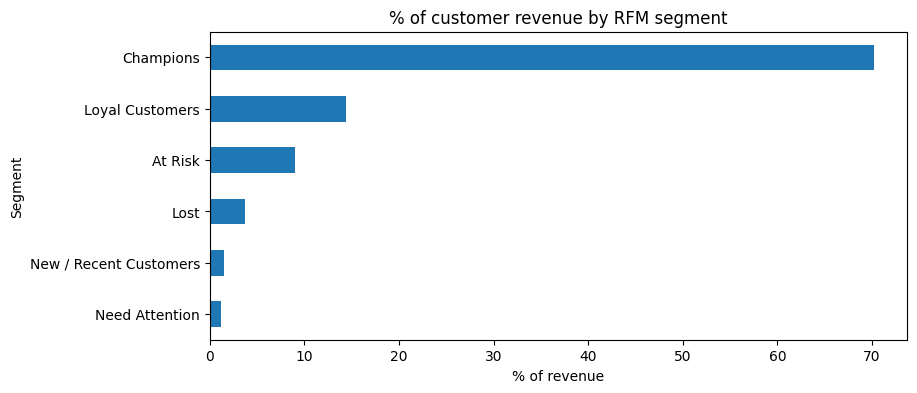

In [63]:
segment_summary['% of revenue'].sort_values().plot(kind='barh', figsize=(9, 4))
plt.title('% of customer revenue by RFM segment')
plt.xlabel('% of revenue')
plt.show()

## 11. K-Means Customer Segmentation

### 11.1 Prepare the data
Recency, Frequency and Monetary are very skewed (a few customers spend more than £100,000) and are on different scales.
K-Means uses distances, so I take the log of each column and then standardise it (mean 0, standard deviation 1).

In [64]:
features = ['Recency', 'Frequency', 'Monetary']
X = StandardScaler().fit_transform(np.log1p(rfm[features]))
X.shape

(5852, 3)

### 11.2 Choose the number of clusters
Two checks for k = 2 to 8: the **elbow** (inertia, lower is better, look for where it stops dropping fast) and the **silhouette score** (higher is better).

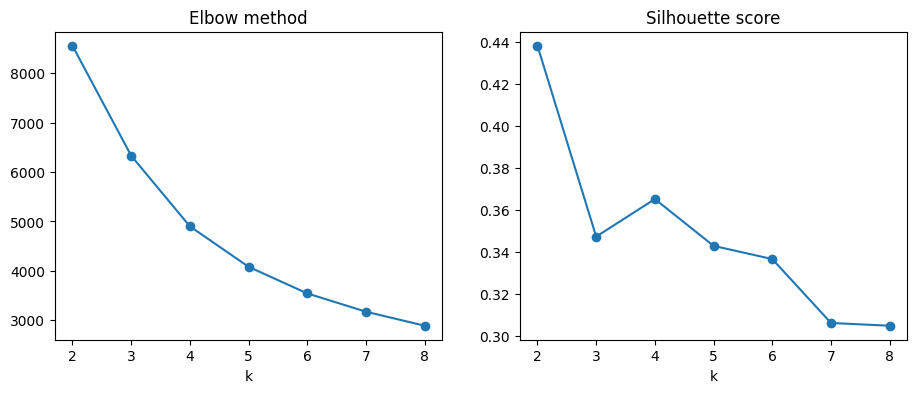

,Inertia,Silhouette
k,,
2,8557.175,0.438
3,6330.325,0.347
4,4899.974,0.365
5,4080.557,0.343
6,3541.240,0.337
7,3170.943,0.306
8,2887.623,0.305


In [65]:
scores = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    scores.append({'k': k, 'Inertia': model.inertia_, 'Silhouette': silhouette_score(X, model.labels_)})
scores = pd.DataFrame(scores).set_index('k')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
scores['Inertia'].plot(marker='o', ax=ax[0], title='Elbow method')
scores['Silhouette'].plot(marker='o', ax=ax[1], title='Silhouette score')
plt.show()
scores.round(3)

The silhouette score and elbow plot are both considered. The highest silhouette score is not automatically the business choice: a very small number of clusters can be statistically compact but too broad to support useful customer actions. Four clusters are retained as a practical segmentation choice only if the displayed profile table shows meaningfully distinct groups. Review the actual scores and profiles after running this notebook; do not treat k =  4 as a universal optimum.


In [66]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(X)
print('Silhouette score:', round(silhouette_score(X, rfm['Cluster']), 3))

cluster_summary = rfm.groupby('Cluster').agg(
    Customers=('Recency', 'size'), Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'), Avg_Monetary=('Monetary', 'mean'),
    Revenue=('Monetary', 'sum')).round(1)
cluster_summary['% of revenue'] = (cluster_summary['Revenue'] / cluster_summary['Revenue'].sum() * 100).round(1)
cluster_summary

Silhouette score: 0.365


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue,% of revenue
Cluster,,,,,,
0,1246,28.2,3.0,841.4,1048418.9,6.2
1,1970,392.5,1.4,316.7,623916.1,3.7
2,1453,227.6,5.1,1920.5,2790445.4,16.6
3,1183,27.7,19.2,10448.1,12360149.2,73.5


### 11.3 Describe the clusters from their full RFM profiles
Cluster IDs are arbitrary. Labels below are generated from each cluster's average Recency, Frequency and Monetary values relative to the customer-level medians. This avoids naming a cluster from spending alone. The labels are descriptive, not ground-truth customer types.


In [ ]:
# Create readable, profile-based labels using all three RFM dimensions.
profile_medians = rfm[['Recency', 'Frequency', 'Monetary']].median()
cluster_names = {}
for cluster_id, profile in cluster_summary.iterrows():
    recency_label = 'Recent' if profile['Avg_Recency'] <= profile_medians['Recency'] else 'Less Recent'
    frequency_label = 'High Frequency' if profile['Avg_Frequency'] >= profile_medians['Frequency'] else 'Low Frequency'
    monetary_label = 'High Value' if profile['Avg_Monetary'] >= profile_medians['Monetary'] else 'Low Value'
    cluster_names[cluster_id] = f'{recency_label} / {frequency_label} / {monetary_label} (C{cluster_id})'

rfm['Cluster_Name'] = rfm['Cluster'].map(cluster_names)
cluster_summary.index = cluster_summary.index.map(cluster_names)
cluster_summary = cluster_summary.sort_values('Revenue', ascending=False)

# Table saved to CSV: original cluster number, descriptive label and full profile.
cluster_profiles = cluster_summary.rename_axis('Cluster_Name').reset_index()
cluster_profiles.insert(
    0, 'Cluster', cluster_profiles['Cluster_Name'].map({v: k for k, v in cluster_names.items()})
)
cluster_profiles


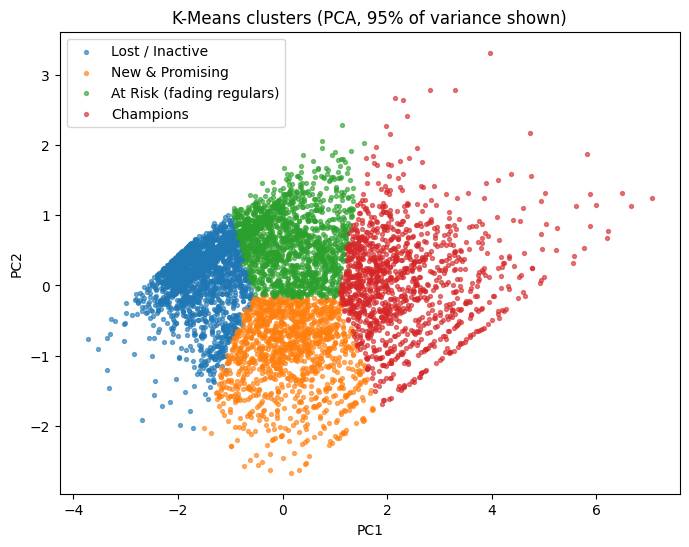

In [68]:
# 2D picture of the clusters using PCA
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X)
plt.figure(figsize=(8, 6))
for name in sorted(rfm['Cluster_Name'].dropna().unique()):
    mask = (rfm['Cluster_Name'] == name).values
    plt.scatter(points[mask, 0], points[mask, 1], s=8, alpha=0.6, label=name)
plt.legend()
plt.title(f'K-Means clusters (PCA, {pca.explained_variance_ratio_.sum() * 100:.0f}% of variance shown)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [69]:
# compare K-Means clusters with the rule-based RFM segments
pd.crosstab(rfm['Segment'], rfm['Cluster_Name'])

Cluster_Name,At Risk (fading regulars),Champions,Lost / Inactive,New & Promising
Segment,,,,
At Risk,624,15,189,0
Champions,117,1060,0,299
Lost,85,0,1424,0
Loyal Customers,587,108,50,462
Need Attention,38,0,267,77
New / Recent Customers,2,0,40,408


**What this means:** the K-Means labels describe each cluster using its average Recency, Frequency and Monetary values relative to the corresponding customer-level medians. 'Recent / High Frequency / High Value' customers are recent purchasers with comparatively frequent and high-value orders; they are important to retain. 'Less Recent' clusters have longer gaps since their last purchase and may merit re-engagement. 'Low Frequency / Low Value' clusters have comparatively fewer orders and lower spend, so encouraging a second or repeat purchase may be useful. These are descriptive profiles, not ground-truth customer types; use the full cluster profile table when deciding on actions.

### 11.4 Check and save

In [70]:
rfm_checks = {
    'One row per customer': len(rfm) == df['CustomerID'].nunique(),
    'RFM revenue = pandas customer revenue': abs(rfm['Monetary'].sum() - customers['Revenue'].sum()) < 1,
    'Recency >= 1': (rfm['Recency'] >= 1).all(),
    'Frequency >= 1': (rfm['Frequency'] >= 1).all(),
    'Scores are between 1 and 5': rfm[['R_score', 'F_score', 'M_score']].apply(lambda c: c.between(1, 5).all()).all(),
    'Every customer has a segment and a cluster': rfm[['Segment', 'Cluster_Name']].notnull().all().all(),
    'Cluster profiles: 4 clusters, customers add up to total': len(cluster_profiles) == 4 and cluster_profiles['Customers'].sum() == len(rfm),
    'Cluster profile revenue % adds up to 100': abs(cluster_profiles['% of revenue'].sum() - 100) < 0.5,
    'K-Means scores cover k = 2 to 8': list(scores.index) == list(range(2, 9)),
    'Segment revenue adds up to total': abs(segment_summary['Revenue'].sum() - rfm['Monetary'].sum()) < 1,
}
for name, result in rfm_checks.items():
    print('PASS' if result else 'FAIL', '-', name)
assert all(rfm_checks.values()), 'Some RFM checks failed'

rfm.reset_index().to_csv('rfm_segments.csv', index=False)
scores_out = scores.reset_index().round(4)
scores_out['Selected'] = scores_out['k'] == 4
scores_out.to_csv('kmeans_evaluation_scores.csv', index=False)
cluster_profiles.to_csv('kmeans_cluster_profiles.csv', index=False)

# check the saved files
for file, rows in {'rfm_segments.csv': len(rfm), 'kmeans_evaluation_scores.csv': len(scores_out),
                   'kmeans_cluster_profiles.csv': len(cluster_profiles)}.items():
    assert len(pd.read_csv(file)) == rows, f'{file} has the wrong number of rows'
    print('Saved and checked:', file, f'({rows} rows)')

PASS - One row per customer
PASS - RFM revenue = pandas customer revenue
PASS - Recency >= 1
PASS - Frequency >= 1
PASS - Scores are between 1 and 5
PASS - Every customer has a segment and a cluster
PASS - Cluster profiles: 4 clusters, customers add up to total
PASS - Cluster profile revenue % adds up to 100
PASS - K-Means scores cover k = 2 to 8
PASS - Segment revenue adds up to total
Saved and checked: rfm_segments.csv (5852 rows)
Saved and checked: kmeans_evaluation_scores.csv (7 rows)
Saved and checked: kmeans_cluster_profiles.csv (4 rows)


### 11.5 Saved RFM and K-Means files
The three files saved above, read back from disk.

In [71]:
pd.read_csv('kmeans_evaluation_scores.csv')

,k,Inertia,Silhouette,Selected
0,2,8557.1753,0.4383,False
1,3,6330.3253,0.3472,False
2,4,4899.9738,0.3652,True
3,5,4080.5574,0.3428,False
4,6,3541.2396,0.3365,False
5,7,3170.9429,0.3060,False
6,8,2887.6229,0.3047,False


In [72]:
pd.read_csv('kmeans_cluster_profiles.csv')

,Cluster,Cluster_Name,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue,% of revenue
0,3,Champions,1183,27.7,19.2,10448.1,12360149.2,73.5
1,2,At Risk (fading regulars),1453,227.6,5.1,1920.5,2790445.4,16.6
2,0,New & Promising,1246,28.2,3.0,841.4,1048418.9,6.2
3,1,Lost / Inactive,1970,392.5,1.4,316.7,623916.1,3.7


In [73]:
rfm_saved = pd.read_csv('rfm_segments.csv')
print('rfm_segments.csv:', rfm_saved.shape)
rfm_saved.head(10)

rfm_segments.csv: (5852, 11)


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment,Cluster,Cluster_Name
0,12346,529,2,169.36,1,2,1,4,Lost,1,Lost / Inactive
1,12347,2,8,4921.53,5,4,5,14,Champions,3,Champions
2,12348,75,5,1658.40,3,4,4,11,Loyal Customers,2,At Risk (fading regulars)
3,12349,19,3,3678.69,5,3,5,13,Loyal Customers,0,New & Promising
4,12350,310,1,294.40,2,1,2,5,Lost,1,Lost / Inactive
5,12351,375,1,300.93,2,1,2,5,Lost,1,Lost / Inactive
6,12352,36,9,1729.54,4,5,4,13,Champions,3,Champions
7,12353,204,2,406.76,2,2,2,6,Lost,1,Lost / Inactive
8,12354,232,1,1079.40,2,1,3,6,Lost,1,Lost / Inactive
9,12355,214,2,947.61,2,2,3,7,Lost,2,At Risk (fading regulars)


## 12. Conclusion
- The raw CSV is loaded into PostgreSQL (`raw_online_retail`) and read into pandas.
- The cleaning workflow records row removals and reasons in `cleaning_log.csv`; guest sales are retained while customer-level analysis uses rows with a CustomerID.
- Clean sales and cancelled orders are loaded into PostgreSQL (`clean_sales`, `cancelled_orders`), and the SQL section runs six customer-level queries.
- RFM scores are calculated at customer level. K-Means evaluates k = 2 to 8 and fits the selected four-cluster solution using log-transformed and standardised RFM features.
- Cluster descriptions use Recency, Frequency and Monetary profiles together. Review the evaluation scores and profile table before making business decisions.
- The validation cells and saved-file checks are designed to stop the workflow if a check fails. A successful result should only be reported after running every cell from top to bottom in an environment with PostgreSQL configured.

**Output files:** `online_retail_II_cleaned.csv`, `online_retail_II_cancellations.csv`, `cleaning_log.csv`,
`validation_report.csv`, `customer_summary.csv`, `customer_transactions.csv`, `customer_queries.sql`, `rfm_segments.csv`, `kmeans_evaluation_scores.csv`, `kmeans_cluster_profiles.csv`
